# Sistema de recomendación para MercadoFT — bitácora técnica

Documento vivo del TFI: qué se midió, qué se decidió y por qué. Cada sección lee los resultados reales de `out/`
(generados por `eda_recomendador.py` y `modelo_eval.py`), así que las tablas y gráficos se actualizan al volver
a correr los scripts.

**Reproducir**
```
uv sync
uv run python eda_recomendador.py --data-dir data --out out
uv run python modelo_eval.py --data-dir data --in out --out out
```
Luego abrir este notebook (kernel del entorno `.venv`).

**Corrida documentada:** datos de producción hasta 13/11/2026. Los números del texto corresponden a esa corrida;
las tablas se recalculan.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "out"
eda = json.load(open(OUT / "eda_resumen.json", encoding="utf-8"))
res = json.load(open(OUT / "resultados_evaluacion.json", encoding="utf-8"))
tabla = pd.read_csv(OUT / "resultados_tabla.csv")
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Datos y hallazgos del EDA

Fuente: CSV exportados de producción (una tabla por archivo). Reglas de limpieza que se decidieron mirando los datos:

- **Elegibilidad de un producto:** `desactivada` falsa **y** `estado_revision = APROBADO`. La columna `activa` es heredada y se ignora.
- **Productos borrados** conservan `producto_original_id` y se recuperan desde `producto_borrado` para armar perfiles, pero **nunca se recomiendan**.
- **Se excluyen** usuarios eliminados y eventos sobre productos propios (el emprendedor mirando lo suyo).
- Los booleanos MySQL `BIT(1)` salen del export como caracteres crudos `\x01` / `\x00`.
- Los usuarios se pseudonimizan con `sha256(sal + id)[:12]`.

In [2]:
f = eda
resumen = pd.Series({
    "Usuarios (no eliminados y verificados)": f["usuarios"]["no_eliminados_y_verificados"],
    "Usuarios con algún evento": f["eventos"]["usuarios_con_algun_evento"],
    "Productos en catálogo": f["productos_flags"]["total"],
    "Productos elegibles": f["productos_elegibles"]["cantidad"],
    "Eventos útiles": f["eventos"]["total"],
    "Pares usuario-producto": f["eventos"]["pares_usuario_producto"],
    "Eventos sobre producto propio excluidos": f["eventos_sobre_producto_propio_excluidos"],
    "Densidad de la matriz (%, usuarios con interacción)": f["densidad_matriz"]["sobre_usuarios_con_interaccion_pct"],
    "Mediana de eventos por usuario": f["concentracion_usuarios"]["mediana_eventos_por_usuario"],
    "Productos con 1–2 usuarios (%)": f["productos_elegibles"]["con_1_o_2_usuarios_pct"],
    "Productos sin ninguna interacción (%)": f["productos_elegibles"]["sin_ninguna_interaccion_pct"],
})
display(resumen.to_frame("valor"))
display(pd.Series(f["eventos"]["por_tipo"]).to_frame("eventos por tipo"))

,valor
Usuarios (no eliminados y verificados),174.000
Usuarios con algún evento,138.000
Productos en catálogo,856.000
Productos elegibles,752.000
Eventos útiles,3032.000
Pares usuario-producto,2114.000
Eventos sobre producto propio excluidos,1002.000
"Densidad de la matriz (%, usuarios con interacción)",1.860
Mediana de eventos por usuario,8.500
Productos con 1–2 usuarios (%),45.200


,eventos por tipo
vista,2854
contacto,115
favorito,40
calificacion,19
compartido,4


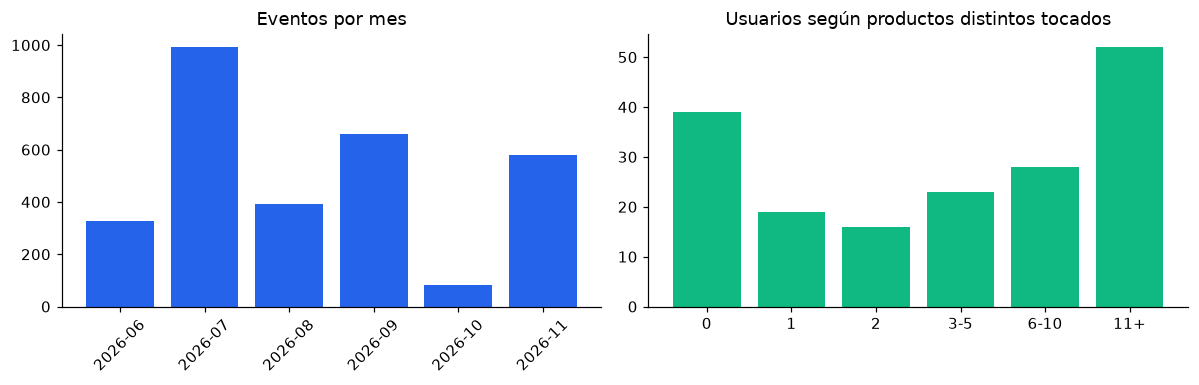

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
m = pd.Series(eda["eventos"]["eventos_por_mes"])
ax[0].bar(m.index, m.values, color="#2563eb"); ax[0].set_title("Eventos por mes"); ax[0].tick_params(axis="x", rotation=45)
d = pd.Series(eda["usuarios_por_cantidad_de_productos_distintos"]["distribucion"])
ax[1].bar(d.index, d.values, color="#10b981"); ax[1].set_title("Usuarios según productos distintos tocados")
plt.tight_layout(); plt.show()

**Lectura**

- Es un dominio **muy ralo**: ~1.9 % de densidad, mediana de 8.5 eventos por usuario y 5 usuarios concentran ~33 % de los eventos.
- **Arranque en frío:** ~42 % de los usuarios tocó menos de 3 productos; ~45 % de los productos lo vieron 1–2 usuarios. Esto justifica un enfoque basado en contenido (no depende de coincidencias entre usuarios).
- **Octubre cayó** por falta de promoción (la promoción se está retomando): es una limitación a declarar, no un error del pipeline.

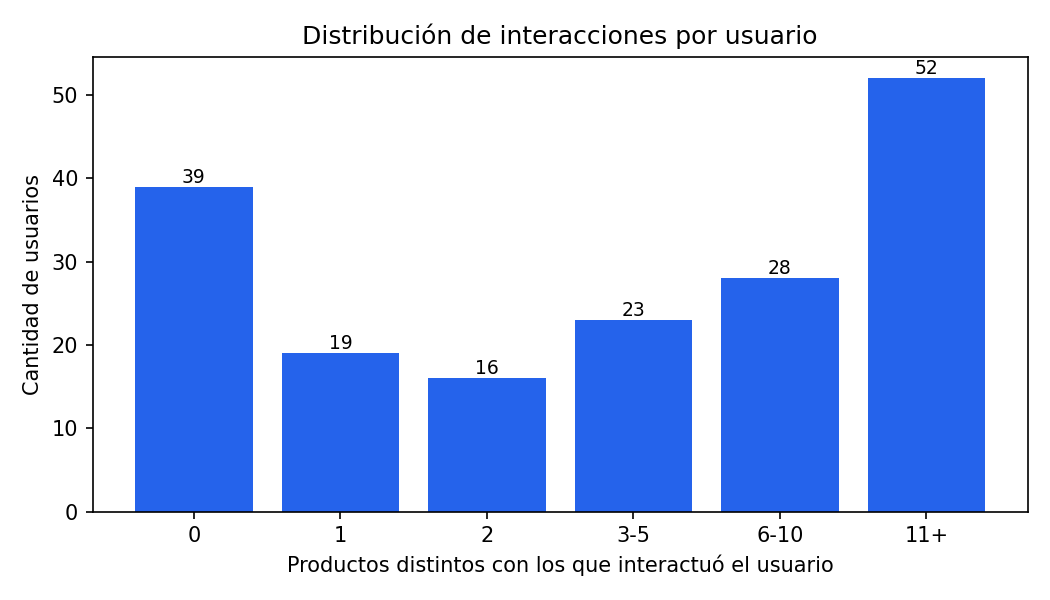

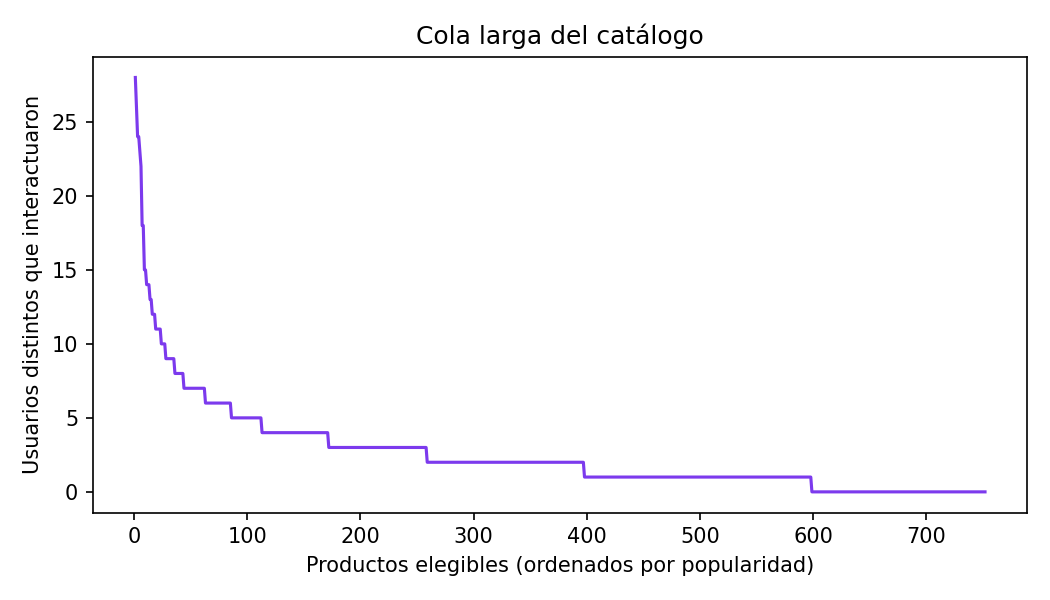

In [4]:
display(Image(OUT / "hist_interacciones_por_usuario.png"))
display(Image(OUT / "long_tail_productos.png"))

## 2. Señales y pesos

Se transforma cada interacción en un peso de preferencia implícita. De cada par (usuario, producto) se toma el **máximo**.

| Señal | Origen | Peso |
|---|---|---|
| vista | `producto_visto` | 1 |
| compartido | `compartido` (tipo PRODUCTO) | 2 |
| favorito | `favorito` | 3 |
| calificación (≥ 4) | `calificacion` | 3 |
| contacto | `consulta` (clic en *contactar al vendedor*) | 5 |
| búsqueda (señal aparte) | `busqueda` | 2 (ver sección 6) |

El contacto es el mejor proxy de éxito de la plataforma porque la venta se cierra por WhatsApp, fuera de la app: la hipótesis se mide por intención de contacto.

## 3. Modelo de contenido

Cada producto es un vector con tres bloques, normalizados y combinados con pesos (texto, categoría, precio):

- **Texto:** TF-IDF de *nombre ×2 + descripción + nombres de categoría* (stopwords en español, n-gramas 1–2, `min_df=2`, `max_df=0.8`, `sublinear_tf`).
- **Categorías:** multi-hot desde `producto_categoria` (incluye siempre `categoria_id`).
- **Precio:** quintil del log-precio, one-hot.

**Perfil del usuario** = suma ponderada de los vectores de los productos con los que interactuó (+ términos buscados, sección 6).
**Puntaje** = similitud coseno entre el perfil y cada candidato. Se excluyen los productos que el usuario ya conocía.

**Baselines:** azar, popularidad (interacciones ponderadas previas) y colaborativo item-kNN.

## 4. Protocolo de evaluación

Todos los protocolos respetan el tiempo: el perfil, las búsquedas y la popularidad se calculan **solo con lo ocurrido antes** de la primera interacción con el producto objetivo, y los candidatos son los productos elegibles ya publicados en ese momento.

- **A_val:** objetivo = penúltimo producto nuevo de cada usuario.
- **A_test:** objetivo = último producto nuevo.
- **A_todos:** A_val + A_test juntos. Sirve para elegir configuración, por lo que es **optimista** para el modelo de contenido.
- **B:** objetivo = último producto **contactado**. No participa de ninguna selección: es la prueba limpia, con muestra chica.

Métricas: Hit@5/10, NDCG@10, MRR, cobertura@10 y % de cola larga en el top-10. Intervalos de confianza del 95 % por bootstrap; diferencias pareadas entre modelos; los empates se resuelven por valor esperado (el azar se calcula analíticamente).

In [5]:
n = res["casos"]; cb = res["casos_con_busqueda_previa"]
display(pd.DataFrame({"casos": n, "con búsqueda previa": cb}).T)
print("Candidatos forzados (objetivo fuera de candidatos):", res["forzados_target_fuera_de_candidatos"])

,A_val,A_test,B
casos,101,119,30
con búsqueda previa,31,45,5


Candidatos forzados (objetivo fuera de candidatos): {'A_todos': 0, 'B': 0}


## 5. Selección de configuración

Se probaron 7 combinaciones de pesos de bloques × 2 esquemas (pesos / binario) × 5 pesos de búsqueda = 70 configuraciones, evaluadas sobre A_todos.

In [6]:
sel = res["seleccion_configuracion"]
g = pd.json_normalize(sel["grid"])
g.columns = [c.replace("pesos_bloques.", "") for c in g.columns]
cols = ["texto", "categoria", "precio", "esquema", "peso_busqueda", "ndcg10_val", "ndcg10_test", "ndcg10_todos", "hit10_todos"]
print("Top 10 por NDCG@10 en A_todos")
display(g.sort_values("ndcg10_todos", ascending=False)[cols].head(10).reset_index(drop=True))

Top 10 por NDCG@10 en A_todos


,texto,categoria,precio,esquema,peso_busqueda,ndcg10_val,ndcg10_test,ndcg10_todos,hit10_todos
0,1,0.000,0.000,pesos,2.000,0.041,0.120,0.084,0.141
1,1,0.000,0.000,binario,2.000,0.045,0.116,0.083,0.141
2,1,0.500,0.300,binario,3.000,0.053,0.108,0.083,0.150
3,1,0.000,0.000,pesos,3.000,0.042,0.116,0.082,0.136
4,1,0.500,0.300,binario,2.000,0.050,0.108,0.082,0.145
5,1,0.000,0.000,pesos,1.000,0.039,0.118,0.081,0.136
6,1,0.500,0.000,binario,3.000,0.049,0.108,0.081,0.136
7,1,0.000,0.000,binario,3.000,0.042,0.113,0.080,0.132
8,1,0.000,0.000,binario,1.000,0.039,0.116,0.080,0.132
9,1,0.500,0.300,binario,1.000,0.050,0.105,0.080,0.150


,texto,categoria,precio,ndcg10_val,ndcg10_test,ndcg10_todos
0,1,0.000,0.000,0.041,0.120,0.084
1,1,0.500,0.000,0.046,0.107,0.079
2,1,1.000,0.000,0.050,0.098,0.076
3,1,0.500,0.300,0.050,0.102,0.078
4,1,1.000,0.300,0.047,0.093,0.072
5,0,1.000,0.000,0.043,0.056,0.050
6,0,1.000,0.300,0.054,0.053,0.053


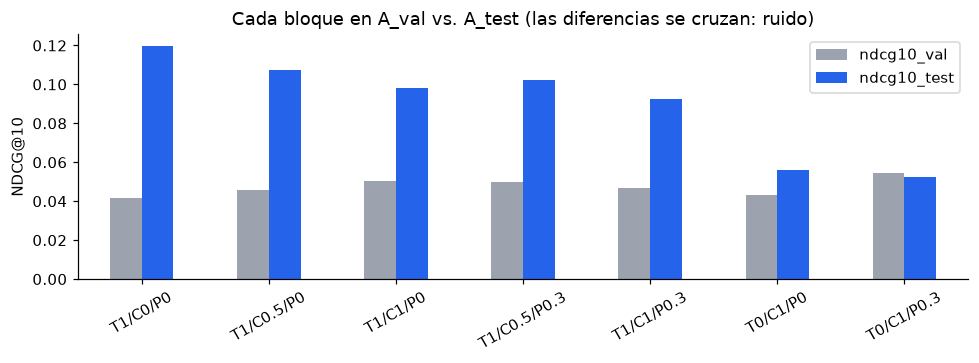

In [7]:
# Efecto de los bloques (esquema 'pesos', peso de búsqueda = 2)
b = g[(g.esquema == "pesos") & (g.peso_busqueda == 2)][["texto", "categoria", "precio", "ndcg10_val", "ndcg10_test", "ndcg10_todos"]]
display(b.reset_index(drop=True))
ax = b.set_index(b.apply(lambda r: f"T{r.texto:g}/C{r.categoria:g}/P{r.precio:g}", axis=1))[["ndcg10_val", "ndcg10_test"]].plot.bar(figsize=(9, 3.4), color=["#9ca3af", "#2563eb"])
ax.set_ylabel("NDCG@10"); ax.set_title("Cada bloque en A_val vs. A_test (las diferencias se cruzan: ruido)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Decisión de configuración**

El máximo del grid fue *solo texto* (categoría 0, precio 0), pero:

- Las diferencias entre configuraciones **no son estadísticamente distinguibles**: unas ganan en A_val y otras en A_test.
- La categoría ya está dentro del texto (los nombres de categoría entran al TF-IDF); el precio es lo único que queda afuera en *solo texto*.
- En B —que no participó de la selección— las configuraciones con categoría y precio rinden igual o mejor.

Se fija **texto 1, categoría 0.5, precio 0.3, esquema por pesos, peso de búsqueda 2**: es más balanceada entre muestras, menos dependiente de la calidad de las descripciones y más fácil de explicar. Se aparta de la regla "máximo en A_todos" (costaba ~0.005 de NDCG) y esa excepción queda documentada acá.

In [8]:
print("Máximo del grid:", sel["elegida_por_maximo"])
print("Configuración final:", sel["config_final"])
est = res["estabilidad_seleccion"]
display(pd.Series(est).drop("nota").to_frame("valor"))
print(est["nota"])

Máximo del grid: {'pesos_bloques': {'texto': 1, 'categoria': 0, 'precio': 0}, 'esquema': 'pesos', 'peso_busqueda': 2, 'ndcg10_val': 0.0414, 'ndcg10_test': 0.1198, 'ndcg10_todos': 0.0838, 'hit10_todos': 0.1409}
Configuración final: {'pesos_bloques': [1, 0.5, 0.3], 'esquema': 'pesos', 'peso_busqueda': 2, 'umbral': 1, 'fuente': 'CONFIG_FINAL (fijada)', 'grid_de_la_final': {'pesos_bloques': {'texto': 1, 'categoria': 0.5, 'precio': 0.3}, 'esquema': 'pesos', 'peso_busqueda': 2, 'ndcg10_val': 0.0497, 'ndcg10_test': 0.1022, 'ndcg10_todos': 0.0781, 'hit10_todos': 0.1364}}


,valor
repeticiones,300
ndcg10_otra_mitad_eligiendo_con_busqueda,0.075
ndcg10_otra_mitad_eligiendo_sin_busqueda,0.070
dif_con_vs_sin_busqueda,0.005
pct_repeticiones_donde_con_busqueda_supera,0.667
pct_repeticiones_que_eligen_w_busqueda_positivo,0.910
pct_repeticiones_que_eligen_texto_positivo,0.987


mide el procedimiento de selección en datos no vistos por esa selección (mitades de usuarios)


**Estabilidad del procedimiento:** se repitió 300 veces "elegir configuración con la mitad de los usuarios y medir en la otra mitad". Eso estima cuánto rinde el *procedimiento* sobre datos que la selección no vio.

## 6. Señal de búsqueda

La tabla `busqueda` guarda el término buscado, el usuario (a veces nulo) y la fecha. Se usa como señal de intención en el perfil:

- Cada término (una vez por usuario) se vectoriza con el mismo TF-IDF y, si es exactamente el nombre de una categoría, también con el bloque de categorías.
- Se suma al perfil con peso `w_b`. El peso 2 está en la escala de las interacciones (equivale a un *compartido*; un contacto pesa 5).
- Solo cuentan búsquedas **anteriores** al producto objetivo. Las búsquedas anónimas (sin `usuario_id`) no se pueden atar a un perfil y se descartan para entrenar; en producción sí podrían usarse a nivel de sesión.

In [9]:
display(pd.Series(res["busquedas"]).to_frame("valor"))
fin = sel["config_final"]["pesos_bloques"]
h = g[(g.texto == fin[0]) & (g.categoria == fin[1]) & (g.precio == fin[2]) & (g.esquema == "pesos")][["peso_busqueda", "ndcg10_val", "ndcg10_test", "ndcg10_todos", "hit10_todos"]]
display(h.reset_index(drop=True))

,valor
filas_total,832
anonimas_descartadas,391
pares_usuario_termino_usados,307
usuarios,62
terminos_distintos,192
terminos_sin_vocabulario_ni_categoria,96


,peso_busqueda,ndcg10_val,ndcg10_test,ndcg10_todos,hit10_todos
0,0.000,0.050,0.091,0.072,0.136
1,0.500,0.050,0.091,0.072,0.132
2,1.000,0.050,0.100,0.077,0.141
3,2.000,0.050,0.102,0.078,0.136
4,3.000,0.049,0.102,0.078,0.136


**Lectura:** la mejora es **chica pero de signo consistente** (la configuración con búsqueda supera a la que no la usa en ~2 de cada 3 repeticiones de la prueba de mitades; en A_val no mejora). Con la configuración final el Hit@10 no cambia (0.136 con y sin búsqueda) y el NDCG@10 sube de 0.072 a 0.078 en A_todos; en B sube de 0.179 a 0.212 con solo 5 casos con búsqueda previa. Solo ~62 usuarios tienen búsquedas utilizables y la mitad de los términos no coincide con vocabulario ni categorías (probablemente nombres de emprendedores). Se la reporta como *refinamiento con evidencia limitada*, no como lo que hace funcionar al modelo.

## 7. Resultados finales

In [10]:
orden = ["random", "popularidad", "colaborativo_itemknn", "contenido_sin_busqueda", "contenido", "hibrido"]
t = tabla[tabla.segmento == "todos"].copy()
t["modelo"] = pd.Categorical(t["modelo"], orden, ordered=True)
cols = ["protocolo", "modelo", "n_casos", "hit5", "hit10", "ndcg10", "mrr", "cobertura10", "pct_cola_top10"]
display(t.sort_values(["protocolo", "modelo"])[cols].reset_index(drop=True))

,protocolo,modelo,n_casos,hit5,hit10,ndcg10,mrr,cobertura10,pct_cola_top10
0,A_todos,random,220,0.011,0.022,0.010,0.014,0.890,0.558
1,A_todos,popularidad,220,0.036,0.077,0.036,0.035,0.059,0.000
2,A_todos,colaborativo_itemknn,220,0.031,0.061,0.032,0.035,0.509,0.269
3,A_todos,contenido_sin_busqueda,220,0.084,0.136,0.072,0.065,0.644,0.514
4,A_todos,contenido,220,0.093,0.136,0.078,0.073,0.637,0.509
5,A_todos,hibrido,220,0.093,0.136,0.078,0.073,0.637,0.509
6,B,random,30,0.043,0.086,0.039,0.037,0.308,0.480
7,B,popularidad,30,0.233,0.272,0.128,0.094,0.041,0.000
8,B,colaborativo_itemknn,30,0.167,0.207,0.118,0.106,0.206,0.210
9,B,contenido_sin_busqueda,30,0.200,0.267,0.179,0.163,0.238,0.320


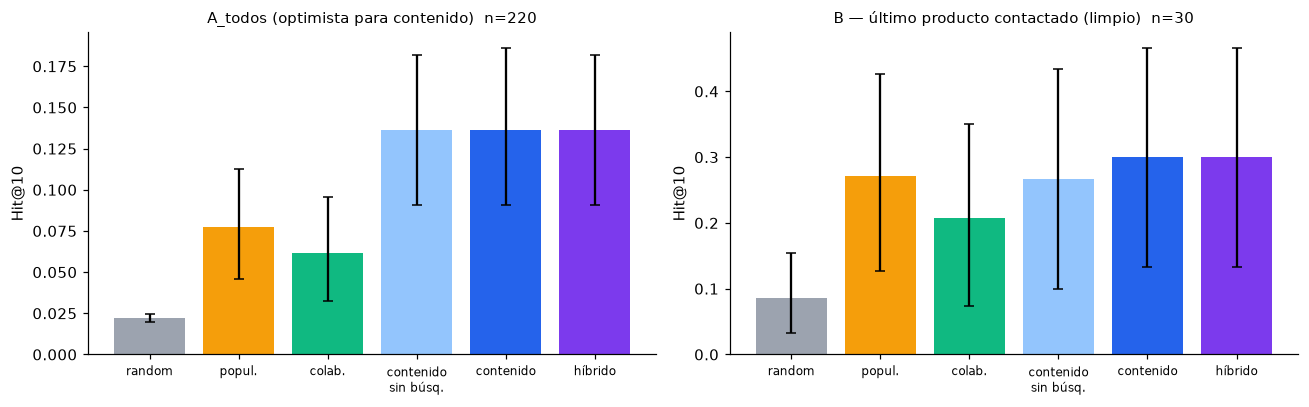

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
nombres = ["random", "popul.", "colab.", "contenido\nsin búsq.", "contenido", "híbrido"]
colores = ["#9ca3af", "#f59e0b", "#10b981", "#93c5fd", "#2563eb", "#7c3aed"]
for ax, proto, titulo in zip(axes, ["A_todos", "B"], ["A_todos (optimista para contenido)", "B — último producto contactado (limpio)"]):
    r = res["resultados"][proto]
    v = [r[m]["hit10"] for m in orden]
    err = [[x - r[m]["hit10_ic95"][0] for x, m in zip(v, orden)], [r[m]["hit10_ic95"][1] - x for x, m in zip(v, orden)]]
    ax.bar(range(len(orden)), v, yerr=err, color=colores, capsize=3)
    ax.set_xticks(range(len(orden))); ax.set_xticklabels(nombres, fontsize=8)
    ax.set_ylabel("Hit@10"); ax.set_title(f"{titulo}  n={r['random']['n_casos']}", fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
filas = []
for proto, mets in res["diferencias"].items():
    for met, comps in mets.items():
        for comp, v in comps.items():
            filas.append({"protocolo": proto, "métrica": met, "comparación": comp, "dif": v["dif"], "IC95 inf": v["ic95"][0], "IC95 sup": v["ic95"][1]})
dif = pd.DataFrame(filas)
dif["excluye 0"] = (dif["IC95 inf"] > 0) | (dif["IC95 sup"] < 0)
display(dif[dif["métrica"] == "hit10"].reset_index(drop=True))

,protocolo,métrica,comparación,dif,IC95 inf,IC95 sup,excluye 0
0,A_todos,hit10,contenido_vs_random,0.115,0.073,0.160,True
1,A_todos,hit10,contenido_vs_popularidad,0.059,0.001,0.114,True
2,A_todos,hit10,contenido_vs_colaborativo,0.075,0.023,0.125,True
3,A_todos,hit10,contenido_vs_sin_busqueda,0.000,-0.018,0.018,False
4,A_todos,hit10,hibrido_vs_popularidad,0.059,0.006,0.112,True
5,B,hit10,contenido_vs_random,0.214,0.075,0.374,True
6,B,hit10,contenido_vs_popularidad,0.029,-0.155,0.200,False
7,B,hit10,contenido_vs_colaborativo,0.093,-0.106,0.291,False
8,B,hit10,contenido_vs_sin_busqueda,0.033,0.000,0.100,False
9,B,hit10,hibrido_vs_popularidad,0.029,-0.157,0.212,False


**Lectura**

- **Contenido vs. azar:** ventaja clara en ambos protocolos.
- **Contenido vs. popularidad y colaborativo:** en A_todos la ventaja sobre popularidad es de +0.059 de Hit@10 con un intervalo que apenas excluye el cero ([0.001, 0.114]), y además es **optimista** (se eligió configuración sobre esos casos). Contra el colaborativo es más clara (+0.075, [0.023, 0.125]). En B (n=30) los intervalos incluyen el cero: es un empate técnico con popularidad.
- **Híbrido:** con umbral 1 es idéntico al contenido (todos los casos evaluables tienen ≥ 1 interacción). Se conserva como regla de arranque en frío: **sin historial → popularidad**.
- **Diversidad (donde más se nota la diferencia):** popularidad recomienda siempre los mismos ~40 productos (cobertura ≈ 6 %, 0 % de cola larga); el contenido cubre ≈ 64 % del catálogo elegible con ≈ 51 % de cola larga. Eso es visibilidad para emprendedores chicos, no solo acierto.

In [13]:
seg = res["segmentos_A_todos"]
filas = [{"historial": s, "modelo": m, "n": r["n_casos"], "hit10": r["hit10"], "ndcg10": r["ndcg10"]} for s, d in seg.items() for m, r in d.items()]
sg = pd.DataFrame(filas)
display(sg.pivot(index="historial", columns="modelo", values="ndcg10").loc[["1-2", "3-5", "6-10", "11+"]])
print("Casos por segmento:", sg.drop_duplicates("historial").set_index("historial")["n"].to_dict())

modelo,colaborativo_itemknn,contenido,popularidad,random
historial,,,,
1-2,0.061,0.117,0.076,0.011
3-5,0.018,0.089,0.029,0.013
6-10,0.064,0.067,0.009,0.009
11+,0.014,0.061,0.034,0.008


Casos por segmento: {'1-2': 42, '3-5': 41, '6-10': 39, '11+': 98}


Los segmentos no tienen intervalos y varios tienen n≈40: son **orientativos**.

## 8. Umbral de personalización

In [14]:
display(pd.DataFrame(res["umbral"]["curva"]))
print("Elegido:", res["umbral"]["elegido"], "| máximo en curva:", res["umbral"]["maximo_en_curva"])

,umbral,hit10,ndcg10,pct_casos_personalizados
0,1,0.136,0.078,1.000
1,2,0.143,0.079,0.891
2,3,0.130,0.070,0.809
3,4,0.120,0.064,0.746
4,5,0.125,0.066,0.691
5,6,0.117,0.059,0.623
6,8,0.109,0.053,0.523


Elegido: 1 | máximo en curva: 2


El umbral 1 vs. 2 difiere en ~0.001 de NDCG (ruido). Se fija **1**: contenido para cualquiera con al menos una interacción; popularidad solo para usuarios sin historial.

## 9. Registro de decisiones

| Decisión | Motivo |
|---|---|
| Enfoque basado en contenido | Densidad ~1.9 %, 42 % de usuarios con < 3 productos, 45 % de productos con 1–2 usuarios |
| Elegibilidad = no desactivada + APROBADO | `activa` es columna heredada |
| Peso de señales 1/2/3/3/5 | Orden por intención; el contacto es el proxy de éxito |
| Evaluación respetando el tiempo | Evitar leakage (un contacto siempre viene precedido de una vista del mismo producto) |
| Config final texto 1 / cat 0.5 / precio 0.3 | Empate estadístico; más balanceada y explicable |
| Señal de búsqueda con peso 2 | Mejora chica y consistente; costo bajo |
| Umbral = 1 | Híbrido ≈ contenido; popularidad solo para usuarios sin historial |

## 10. Limitaciones a declarar en la tesis

- **Volumen bajo y octubre con poca actividad** (poca promoción): intervalos anchos.
- **B tiene 30 casos** (5 con búsqueda previa): no permite conclusiones firmes sobre contacto.
- **A_todos es optimista** para el contenido; cada usuario aporta hasta 2 casos y los intervalos los tratan como independientes.
- **Popularidad es un rival fuerte** en plataformas chicas; la ventaja del enfoque es sobre todo diversidad y cobertura de cola larga.
- La señal de búsqueda cubre ~62 usuarios y la mitad de los términos no se pueden mapear a contenido.
- Evaluación **offline**: el impacto real en contactos requiere una prueba en producción (A/B o comparación antes/después).

## 11. Próximos pasos

1. Reglas de arranque en frío en la API (sin historial → popularidad; búsqueda de sesión para anónimos).
2. API FastAPI (`POST /recomendar`, `GET /health`, API key, recarga atómica del modelo).
3. Exportación del snapshot desde el backend al bucket y entrenamiento nocturno.
4. Cliente en Spring Boot con circuit breaker y "retoque" (filtrar contra el estado real, excluir contactados, reordenar por categoría de la sesión).
5. Pruebas en DEV/PROD y redacción de metodología, resultados y limitaciones.